# Aula 1 — Machine Learning para Sistemas de Engenharia
## Do dado ao surrogate model: previsão de resistência de casco com MLP e RBF

**Disciplina:** Otimização — IA aplicada à Engenharia Naval e Oceânica
**Exemplo:** Yacht Hydrodynamics Dataset (Delft Ship Hydromechanics Laboratory)

Este notebook é leve o suficiente para rodar em CPU em poucos segundos. A ideia é acompanhar o fluxo:

`dado de engenharia → Machine Learning → predição rápida → projeto/otimização`

e comparar duas famílias de surrogate treinadas sobre os **mesmos dados**:

| | MLP (rede neural) | RBF (Gaussian Process com kernel RBF) |
|---|---|---|
| Tipo de modelo | paramétrico (nº fixo de pesos) | não-paramétrico (usa os próprios pontos de treino) |
| Treino | gradiente + backpropagation, várias épocas | máxima verossimilhança dos hiperparâmetros + solução de um sistema linear |
| Saída | só a predição $\hat{y}$ | predição $\mu(\mathbf{x})$ **e** incerteza $\sigma(\mathbf{x})$ |
| Escala com nº de dados | bem (custo linear por época) | mal ($\mathcal{O}(N^3)$), ótimo para poucas centenas de pontos |

**Sobre o dataset:** 308 ensaios em tanque de reboque com modelos em escala, realizados no Delft Ship
Hydromechanics Laboratory, cobrindo 22 formas de casco derivadas de uma forma-mãe próxima ao *Standfast 43*
(Frans Maas). Cada casco foi ensaiado em 14 valores do número de Froude (0.125 a 0.450). As 6 entradas são
coeficientes geométricos adimensionais + Fn; a saída é a resistência residual por unidade de peso deslocado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(0)
np.random.seed(0)

DEVICE = "cpu"  # notebook pensado para rodar sem GPU
print("PyTorch:", torch.__version__, "| device:", DEVICE)


PyTorch: 2.14.1+cu130 | device: cpu


## 1. Carregar e explorar os dados

### O que significa cada coluna

Notação: $L$ = comprimento na linha d'água, $B$ = boca (largura máxima na linha d'água), $T$ = calado,
$\nabla$ = volume deslocado, $A_M$ = área da seção mestra (seção transversal submersa de maior área),
$V$ = velocidade, $g$ = aceleração da gravidade.

| Coluna | Símbolo / definição | Faixa no dataset | Significado físico |
|---|---|---|---|
| `center_of_buoyancy` | $LCB$ (% de $L$, em relação à meia-nau; negativo = à ré) | −5.0 a 0.0 | Posição longitudinal do centro de carena (centroide do volume submerso). Indica como o volume está distribuído entre proa e popa; afeta o trim e o padrão de ondas geradas. |
| `prismatic_coefficient` | $C_P = \dfrac{\nabla}{A_M \, L}$ | 0.53 a 0.60 | Quão "cheias" são as extremidades do casco. $C_P$ alto = proa e popa cheias (mais volume útil, em geral mais resistência de ondas em alta velocidade); $C_P$ baixo = extremidades finas. |
| `length_displacement` | $\dfrac{L}{\nabla^{1/3}}$ | 4.34 a 5.14 | Esbeltez do casco: comprimento em relação ao "tamanho" do volume deslocado. Valores altos = casco longo e leve para seu comprimento, típico de menor resistência por unidade de peso. |
| `beam_draught_ratio` | $\dfrac{B}{T}$ | 2.81 a 5.35 | Razão boca/calado. Alto = casco largo e raso (mais estabilidade de forma, maior área molhada relativa); baixo = casco estreito e profundo. |
| `length_beam_ratio` | $\dfrac{L}{B}$ | 2.73 a 3.64 | Razão comprimento/boca. Alto = casco esguio (menos resistência de ondas, menos estabilidade inicial); baixo = casco "bojudo". |
| `froude_number` | $Fn = \dfrac{V}{\sqrt{g\,L}}$ | 0.125 a 0.450 | Velocidade adimensional. Compara o comprimento do casco com o comprimento da onda que ele gera. Perto de $Fn \approx 0.4$ a onda gerada tem comprimento próximo de $L$ e a resistência de ondas cresce de forma abrupta. |
| `resistance` | $R_R / \Delta$ (resistência residual por peso deslocado, $\Delta = \rho g \nabla$) | 0.01 a 62.4 | **Saída do modelo.** Parcela da resistência que sobra depois de descontar o atrito. |

### Por que a saída é a resistência *residual*?

A resistência total ao avanço costuma ser decomposta (hipótese de Froude) em

$$
R_T = R_F + R_R ,
$$

onde $R_F$ é a resistência de atrito, que depende do número de Reynolds $Re = VL/\nu$ e é bem estimada por
linhas empíricas, por exemplo a linha ITTC-57:

$$
C_F = \frac{0.075}{(\log_{10} Re - 2)^2}, \qquad R_F = \tfrac12 \rho V^2 S\, C_F ,
$$

e $R_R$ é a resistência residual (essencialmente formação de ondas + efeitos de forma), que depende da
geometria e de $Fn$, e **não** tem uma fórmula fechada simples. É exatamente essa parcela "difícil" que
o surrogate vai aprender a partir dos ensaios:

$$
\frac{R_R}{\Delta} \approx f\big(LCB,\; C_P,\; L/\nabla^{1/3},\; B/T,\; L/B,\; Fn\big).
$$

Como todas as entradas são adimensionais, um mesmo modelo vale para cascos geometricamente semelhantes
de tamanhos diferentes (semelhança de Froude).

In [2]:
from pathlib import Path
import io

LOCAL_PATH = Path("data/yacht_hydrodynamics.csv")

# Copia embutida do dataset (mesmo conteudo do arquivo local) para garantir que o
# notebook rode em qualquer ambiente -- local, Google Colab, maquina de outro aluno --
# mesmo que o CSV nao tenha sido enviado junto com o .ipynb. Isso evita depender de um
# link externo (que pode cair ou mudar de endereco) para algo essencial na hora da aula.
_EMBEDDED_CSV = """center_of_buoyancy,prismatic_coefficient,length_displacement,beam_draught_ratio,length_beam_ratio,froude_number,resistance
-2.3,0.568,4.78,3.99,3.17,0.125,0.11
-2.3,0.568,4.78,3.99,3.17,0.150,0.27
-2.3,0.568,4.78,3.99,3.17,0.175,0.47
-2.3,0.568,4.78,3.99,3.17,0.200,0.78
-2.3,0.568,4.78,3.99,3.17,0.225,1.18
-2.3,0.568,4.78,3.99,3.17,0.250,1.82
-2.3,0.568,4.78,3.99,3.17,0.275,2.61
-2.3,0.568,4.78,3.99,3.17,0.300,3.76
-2.3,0.568,4.78,3.99,3.17,0.325,4.99
-2.3,0.568,4.78,3.99,3.17,0.350,7.16
-2.3,0.568,4.78,3.99,3.17,0.375,11.93
-2.3,0.568,4.78,3.99,3.17,0.400,20.11
-2.3,0.568,4.78,3.99,3.17,0.425,32.75
-2.3,0.568,4.78,3.99,3.17,0.450,49.49
-2.3,0.569,4.78,3.04,3.64,0.125,0.04
-2.3,0.569,4.78,3.04,3.64,0.150,0.17
-2.3,0.569,4.78,3.04,3.64,0.175,0.37
-2.3,0.569,4.78,3.04,3.64,0.200,0.66
-2.3,0.569,4.78,3.04,3.64,0.225,1.06
-2.3,0.569,4.78,3.04,3.64,0.250,1.59
-2.3,0.569,4.78,3.04,3.64,0.275,2.33
-2.3,0.569,4.78,3.04,3.64,0.300,3.29
-2.3,0.569,4.78,3.04,3.64,0.325,4.61
-2.3,0.569,4.78,3.04,3.64,0.350,7.11
-2.3,0.569,4.78,3.04,3.64,0.375,11.99
-2.3,0.569,4.78,3.04,3.64,0.400,21.09
-2.3,0.569,4.78,3.04,3.64,0.425,35.01
-2.3,0.569,4.78,3.04,3.64,0.450,51.80
-2.3,0.565,4.78,5.35,2.76,0.125,0.09
-2.3,0.565,4.78,5.35,2.76,0.150,0.29
-2.3,0.565,4.78,5.35,2.76,0.175,0.56
-2.3,0.565,4.78,5.35,2.76,0.200,0.86
-2.3,0.565,4.78,5.35,2.76,0.225,1.31
-2.3,0.565,4.78,5.35,2.76,0.250,1.99
-2.3,0.565,4.78,5.35,2.76,0.275,2.94
-2.3,0.565,4.78,5.35,2.76,0.300,4.21
-2.3,0.565,4.78,5.35,2.76,0.325,5.54
-2.3,0.565,4.78,5.35,2.76,0.350,8.25
-2.3,0.565,4.78,5.35,2.76,0.375,13.08
-2.3,0.565,4.78,5.35,2.76,0.400,21.40
-2.3,0.565,4.78,5.35,2.76,0.425,33.14
-2.3,0.565,4.78,5.35,2.76,0.450,50.14
-2.3,0.564,5.10,3.95,3.53,0.125,0.20
-2.3,0.564,5.10,3.95,3.53,0.150,0.35
-2.3,0.564,5.10,3.95,3.53,0.175,0.65
-2.3,0.564,5.10,3.95,3.53,0.200,0.93
-2.3,0.564,5.10,3.95,3.53,0.225,1.37
-2.3,0.564,5.10,3.95,3.53,0.250,1.97
-2.3,0.564,5.10,3.95,3.53,0.275,2.83
-2.3,0.564,5.10,3.95,3.53,0.300,3.99
-2.3,0.564,5.10,3.95,3.53,0.325,5.19
-2.3,0.564,5.10,3.95,3.53,0.350,8.03
-2.3,0.564,5.10,3.95,3.53,0.375,12.86
-2.3,0.564,5.10,3.95,3.53,0.400,21.51
-2.3,0.564,5.10,3.95,3.53,0.425,33.97
-2.3,0.564,5.10,3.95,3.53,0.450,50.36
-2.4,0.574,4.36,3.96,2.76,0.125,0.20
-2.4,0.574,4.36,3.96,2.76,0.150,0.35
-2.4,0.574,4.36,3.96,2.76,0.175,0.65
-2.4,0.574,4.36,3.96,2.76,0.200,0.93
-2.4,0.574,4.36,3.96,2.76,0.225,1.37
-2.4,0.574,4.36,3.96,2.76,0.250,1.97
-2.4,0.574,4.36,3.96,2.76,0.275,2.83
-2.4,0.574,4.36,3.96,2.76,0.300,3.99
-2.4,0.574,4.36,3.96,2.76,0.325,5.19
-2.4,0.574,4.36,3.96,2.76,0.350,8.03
-2.4,0.574,4.36,3.96,2.76,0.375,12.86
-2.4,0.574,4.36,3.96,2.76,0.400,21.51
-2.4,0.574,4.36,3.96,2.76,0.425,33.97
-2.4,0.574,4.36,3.96,2.76,0.450,50.36
-2.4,0.568,4.34,2.98,3.15,0.125,0.12
-2.4,0.568,4.34,2.98,3.15,0.150,0.26
-2.4,0.568,4.34,2.98,3.15,0.175,0.43
-2.4,0.568,4.34,2.98,3.15,0.200,0.69
-2.4,0.568,4.34,2.98,3.15,0.225,1.09
-2.4,0.568,4.34,2.98,3.15,0.250,1.67
-2.4,0.568,4.34,2.98,3.15,0.275,2.46
-2.4,0.568,4.34,2.98,3.15,0.300,3.43
-2.4,0.568,4.34,2.98,3.15,0.325,4.62
-2.4,0.568,4.34,2.98,3.15,0.350,6.86
-2.4,0.568,4.34,2.98,3.15,0.375,11.56
-2.4,0.568,4.34,2.98,3.15,0.400,20.63
-2.4,0.568,4.34,2.98,3.15,0.425,34.50
-2.4,0.568,4.34,2.98,3.15,0.450,54.23
-2.3,0.562,5.14,4.95,3.17,0.125,0.28
-2.3,0.562,5.14,4.95,3.17,0.150,0.44
-2.3,0.562,5.14,4.95,3.17,0.175,0.70
-2.3,0.562,5.14,4.95,3.17,0.200,1.07
-2.3,0.562,5.14,4.95,3.17,0.225,1.57
-2.3,0.562,5.14,4.95,3.17,0.250,2.23
-2.3,0.562,5.14,4.95,3.17,0.275,3.09
-2.3,0.562,5.14,4.95,3.17,0.300,4.09
-2.3,0.562,5.14,4.95,3.17,0.325,5.82
-2.3,0.562,5.14,4.95,3.17,0.350,8.28
-2.3,0.562,5.14,4.95,3.17,0.375,12.80
-2.3,0.562,5.14,4.95,3.17,0.400,20.41
-2.3,0.562,5.14,4.95,3.17,0.425,32.34
-2.3,0.562,5.14,4.95,3.17,0.450,47.29
-2.4,0.585,4.78,3.84,3.32,0.125,0.20
-2.4,0.585,4.78,3.84,3.32,0.150,0.38
-2.4,0.585,4.78,3.84,3.32,0.175,0.64
-2.4,0.585,4.78,3.84,3.32,0.200,0.97
-2.4,0.585,4.78,3.84,3.32,0.225,1.36
-2.4,0.585,4.78,3.84,3.32,0.250,1.98
-2.4,0.585,4.78,3.84,3.32,0.275,2.91
-2.4,0.585,4.78,3.84,3.32,0.300,4.35
-2.4,0.585,4.78,3.84,3.32,0.325,5.79
-2.4,0.585,4.78,3.84,3.32,0.350,8.04
-2.4,0.585,4.78,3.84,3.32,0.375,12.15
-2.4,0.585,4.78,3.84,3.32,0.400,19.18
-2.4,0.585,4.78,3.84,3.32,0.425,30.09
-2.4,0.585,4.78,3.84,3.32,0.450,44.38
-2.2,0.546,4.78,4.13,3.07,0.125,0.15
-2.2,0.546,4.78,4.13,3.07,0.150,0.32
-2.2,0.546,4.78,4.13,3.07,0.175,0.55
-2.2,0.546,4.78,4.13,3.07,0.200,0.86
-2.2,0.546,4.78,4.13,3.07,0.225,1.24
-2.2,0.546,4.78,4.13,3.07,0.250,1.76
-2.2,0.546,4.78,4.13,3.07,0.275,2.49
-2.2,0.546,4.78,4.13,3.07,0.300,3.45
-2.2,0.546,4.78,4.13,3.07,0.325,4.83
-2.2,0.546,4.78,4.13,3.07,0.350,7.37
-2.2,0.546,4.78,4.13,3.07,0.375,12.76
-2.2,0.546,4.78,4.13,3.07,0.400,21.99
-2.2,0.546,4.78,4.13,3.07,0.425,35.64
-2.2,0.546,4.78,4.13,3.07,0.450,53.07
0.0,0.565,4.77,3.99,3.15,0.125,0.11
0.0,0.565,4.77,3.99,3.15,0.150,0.24
0.0,0.565,4.77,3.99,3.15,0.175,0.49
0.0,0.565,4.77,3.99,3.15,0.200,0.79
0.0,0.565,4.77,3.99,3.15,0.225,1.28
0.0,0.565,4.77,3.99,3.15,0.250,1.96
0.0,0.565,4.77,3.99,3.15,0.275,2.88
0.0,0.565,4.77,3.99,3.15,0.300,4.14
0.0,0.565,4.77,3.99,3.15,0.325,5.96
0.0,0.565,4.77,3.99,3.15,0.350,9.07
0.0,0.565,4.77,3.99,3.15,0.375,14.93
0.0,0.565,4.77,3.99,3.15,0.400,24.13
0.0,0.565,4.77,3.99,3.15,0.425,38.12
0.0,0.565,4.77,3.99,3.15,0.450,55.44
-5.0,0.565,4.77,3.99,3.15,0.125,0.07
-5.0,0.565,4.77,3.99,3.15,0.150,0.18
-5.0,0.565,4.77,3.99,3.15,0.175,0.40
-5.0,0.565,4.77,3.99,3.15,0.200,0.70
-5.0,0.565,4.77,3.99,3.15,0.225,1.14
-5.0,0.565,4.77,3.99,3.15,0.250,1.83
-5.0,0.565,4.77,3.99,3.15,0.275,2.77
-5.0,0.565,4.77,3.99,3.15,0.300,4.12
-5.0,0.565,4.77,3.99,3.15,0.325,5.41
-5.0,0.565,4.77,3.99,3.15,0.350,7.87
-5.0,0.565,4.77,3.99,3.15,0.375,12.71
-5.0,0.565,4.77,3.99,3.15,0.400,21.02
-5.0,0.565,4.77,3.99,3.15,0.425,34.58
-5.0,0.565,4.77,3.99,3.15,0.450,51.77
0.0,0.565,5.10,3.94,3.51,0.125,0.08
0.0,0.565,5.10,3.94,3.51,0.150,0.26
0.0,0.565,5.10,3.94,3.51,0.175,0.50
0.0,0.565,5.10,3.94,3.51,0.200,0.83
0.0,0.565,5.10,3.94,3.51,0.225,1.28
0.0,0.565,5.10,3.94,3.51,0.250,1.90
0.0,0.565,5.10,3.94,3.51,0.275,2.68
0.0,0.565,5.10,3.94,3.51,0.300,3.76
0.0,0.565,5.10,3.94,3.51,0.325,5.57
0.0,0.565,5.10,3.94,3.51,0.350,8.76
0.0,0.565,5.10,3.94,3.51,0.375,14.24
0.0,0.565,5.10,3.94,3.51,0.400,23.05
0.0,0.565,5.10,3.94,3.51,0.425,35.46
0.0,0.565,5.10,3.94,3.51,0.450,51.99
-5.0,0.565,5.10,3.94,3.51,0.125,0.08
-5.0,0.565,5.10,3.94,3.51,0.150,0.24
-5.0,0.565,5.10,3.94,3.51,0.175,0.45
-5.0,0.565,5.10,3.94,3.51,0.200,0.77
-5.0,0.565,5.10,3.94,3.51,0.225,1.19
-5.0,0.565,5.10,3.94,3.51,0.250,1.76
-5.0,0.565,5.10,3.94,3.51,0.275,2.59
-5.0,0.565,5.10,3.94,3.51,0.300,3.85
-5.0,0.565,5.10,3.94,3.51,0.325,5.27
-5.0,0.565,5.10,3.94,3.51,0.350,7.74
-5.0,0.565,5.10,3.94,3.51,0.375,12.40
-5.0,0.565,5.10,3.94,3.51,0.400,20.91
-5.0,0.565,5.10,3.94,3.51,0.425,33.23
-5.0,0.565,5.10,3.94,3.51,0.450,49.14
-2.3,0.530,5.11,3.69,3.51,0.125,0.08
-2.3,0.530,5.11,3.69,3.51,0.150,0.25
-2.3,0.530,5.11,3.69,3.51,0.175,0.46
-2.3,0.530,5.11,3.69,3.51,0.200,0.75
-2.3,0.530,5.11,3.69,3.51,0.225,1.11
-2.3,0.530,5.11,3.69,3.51,0.250,1.57
-2.3,0.530,5.11,3.69,3.51,0.275,2.17
-2.3,0.530,5.11,3.69,3.51,0.300,2.98
-2.3,0.530,5.11,3.69,3.51,0.325,4.42
-2.3,0.530,5.11,3.69,3.51,0.350,7.84
-2.3,0.530,5.11,3.69,3.51,0.375,14.11
-2.3,0.530,5.11,3.69,3.51,0.400,24.14
-2.3,0.530,5.11,3.69,3.51,0.425,37.95
-2.3,0.530,5.11,3.69,3.51,0.450,55.17
-2.3,0.530,4.76,3.68,3.16,0.125,0.10
-2.3,0.530,4.76,3.68,3.16,0.150,0.23
-2.3,0.530,4.76,3.68,3.16,0.175,0.47
-2.3,0.530,4.76,3.68,3.16,0.200,0.76
-2.3,0.530,4.76,3.68,3.16,0.225,1.15
-2.3,0.530,4.76,3.68,3.16,0.250,1.65
-2.3,0.530,4.76,3.68,3.16,0.275,2.28
-2.3,0.530,4.76,3.68,3.16,0.300,3.09
-2.3,0.530,4.76,3.68,3.16,0.325,4.41
-2.3,0.530,4.76,3.68,3.16,0.350,7.51
-2.3,0.530,4.76,3.68,3.16,0.375,13.77
-2.3,0.530,4.76,3.68,3.16,0.400,23.96
-2.3,0.530,4.76,3.68,3.16,0.425,37.38
-2.3,0.530,4.76,3.68,3.16,0.450,56.46
-2.3,0.530,4.34,2.81,3.15,0.125,0.05
-2.3,0.530,4.34,2.81,3.15,0.150,0.17
-2.3,0.530,4.34,2.81,3.15,0.175,0.35
-2.3,0.530,4.34,2.81,3.15,0.200,0.63
-2.3,0.530,4.34,2.81,3.15,0.225,1.01
-2.3,0.530,4.34,2.81,3.15,0.250,1.43
-2.3,0.530,4.34,2.81,3.15,0.275,2.05
-2.3,0.530,4.34,2.81,3.15,0.300,2.73
-2.3,0.530,4.34,2.81,3.15,0.325,3.87
-2.3,0.530,4.34,2.81,3.15,0.350,7.19
-2.3,0.530,4.34,2.81,3.15,0.375,13.96
-2.3,0.530,4.34,2.81,3.15,0.400,25.18
-2.3,0.530,4.34,2.81,3.15,0.425,41.34
-2.3,0.530,4.34,2.81,3.15,0.450,62.42
0.0,0.600,4.78,4.24,3.15,0.125,0.03
0.0,0.600,4.78,4.24,3.15,0.150,0.18
0.0,0.600,4.78,4.24,3.15,0.175,0.40
0.0,0.600,4.78,4.24,3.15,0.200,0.73
0.0,0.600,4.78,4.24,3.15,0.225,1.30
0.0,0.600,4.78,4.24,3.15,0.250,2.16
0.0,0.600,4.78,4.24,3.15,0.275,3.35
0.0,0.600,4.78,4.24,3.15,0.300,5.06
0.0,0.600,4.78,4.24,3.15,0.325,7.14
0.0,0.600,4.78,4.24,3.15,0.350,10.36
0.0,0.600,4.78,4.24,3.15,0.375,15.25
0.0,0.600,4.78,4.24,3.15,0.400,23.15
0.0,0.600,4.78,4.24,3.15,0.425,34.62
0.0,0.600,4.78,4.24,3.15,0.450,51.50
-5.0,0.600,4.78,4.24,3.15,0.125,0.06
-5.0,0.600,4.78,4.24,3.15,0.150,0.15
-5.0,0.600,4.78,4.24,3.15,0.175,0.34
-5.0,0.600,4.78,4.24,3.15,0.200,0.63
-5.0,0.600,4.78,4.24,3.15,0.225,1.13
-5.0,0.600,4.78,4.24,3.15,0.250,1.85
-5.0,0.600,4.78,4.24,3.15,0.275,2.84
-5.0,0.600,4.78,4.24,3.15,0.300,4.34
-5.0,0.600,4.78,4.24,3.15,0.325,6.20
-5.0,0.600,4.78,4.24,3.15,0.350,8.62
-5.0,0.600,4.78,4.24,3.15,0.375,12.49
-5.0,0.600,4.78,4.24,3.15,0.400,20.41
-5.0,0.600,4.78,4.24,3.15,0.425,32.46
-5.0,0.600,4.78,4.24,3.15,0.450,50.94
0.0,0.530,4.78,3.75,3.15,0.125,0.16
0.0,0.530,4.78,3.75,3.15,0.150,0.32
0.0,0.530,4.78,3.75,3.15,0.175,0.59
0.0,0.530,4.78,3.75,3.15,0.200,0.92
0.0,0.530,4.78,3.75,3.15,0.225,1.37
0.0,0.530,4.78,3.75,3.15,0.250,1.94
0.0,0.530,4.78,3.75,3.15,0.275,2.62
0.0,0.530,4.78,3.75,3.15,0.300,3.70
0.0,0.530,4.78,3.75,3.15,0.325,5.45
0.0,0.530,4.78,3.75,3.15,0.350,9.45
0.0,0.530,4.78,3.75,3.15,0.375,16.31
0.0,0.530,4.78,3.75,3.15,0.400,27.34
0.0,0.530,4.78,3.75,3.15,0.425,41.77
0.0,0.530,4.78,3.75,3.15,0.450,60.85
-5.0,0.530,4.78,3.75,3.15,0.125,0.09
-5.0,0.530,4.78,3.75,3.15,0.150,0.24
-5.0,0.530,4.78,3.75,3.15,0.175,0.47
-5.0,0.530,4.78,3.75,3.15,0.200,0.78
-5.0,0.530,4.78,3.75,3.15,0.225,1.21
-5.0,0.530,4.78,3.75,3.15,0.250,1.85
-5.0,0.530,4.78,3.75,3.15,0.275,2.62
-5.0,0.530,4.78,3.75,3.15,0.300,3.69
-5.0,0.530,4.78,3.75,3.15,0.325,5.07
-5.0,0.530,4.78,3.75,3.15,0.350,7.95
-5.0,0.530,4.78,3.75,3.15,0.375,13.73
-5.0,0.530,4.78,3.75,3.15,0.400,23.55
-5.0,0.530,4.78,3.75,3.15,0.425,37.14
-5.0,0.530,4.78,3.75,3.15,0.450,55.87
-2.3,0.600,5.10,4.17,3.51,0.125,0.01
-2.3,0.600,5.10,4.17,3.51,0.150,0.16
-2.3,0.600,5.10,4.17,3.51,0.175,0.39
-2.3,0.600,5.10,4.17,3.51,0.200,0.73
-2.3,0.600,5.10,4.17,3.51,0.225,1.24
-2.3,0.600,5.10,4.17,3.51,0.250,1.96
-2.3,0.600,5.10,4.17,3.51,0.275,3.04
-2.3,0.600,5.10,4.17,3.51,0.300,4.46
-2.3,0.600,5.10,4.17,3.51,0.325,6.31
-2.3,0.600,5.10,4.17,3.51,0.350,8.68
-2.3,0.600,5.10,4.17,3.51,0.375,12.39
-2.3,0.600,5.10,4.17,3.51,0.400,20.14
-2.3,0.600,5.10,4.17,3.51,0.425,31.77
-2.3,0.600,5.10,4.17,3.51,0.450,47.13
-2.3,0.600,4.34,4.23,2.73,0.125,0.04
-2.3,0.600,4.34,4.23,2.73,0.150,0.17
-2.3,0.600,4.34,4.23,2.73,0.175,0.36
-2.3,0.600,4.34,4.23,2.73,0.200,0.64
-2.3,0.600,4.34,4.23,2.73,0.225,1.02
-2.3,0.600,4.34,4.23,2.73,0.250,1.62
-2.3,0.600,4.34,4.23,2.73,0.275,2.63
-2.3,0.600,4.34,4.23,2.73,0.300,4.15
-2.3,0.600,4.34,4.23,2.73,0.325,6.00
-2.3,0.600,4.34,4.23,2.73,0.350,8.47
-2.3,0.600,4.34,4.23,2.73,0.375,12.27
-2.3,0.600,4.34,4.23,2.73,0.400,19.59
-2.3,0.600,4.34,4.23,2.73,0.425,30.48
-2.3,0.600,4.34,4.23,2.73,0.450,46.66
"""

if LOCAL_PATH.exists():
    df = pd.read_csv(LOCAL_PATH)
    print(f"Dados carregados do arquivo local: {LOCAL_PATH}")
else:
    df = pd.read_csv(io.StringIO(_EMBEDDED_CSV))
    print("Arquivo local nao encontrado -- usando copia embutida do dataset (mesmo conteudo).")

print(df.shape)
df.head()


Arquivo local nao encontrado -- usando copia embutida do dataset (mesmo conteudo).
(308, 7)


,center_of_buoyancy,prismatic_coefficient,length_displacement,beam_draught_ratio,length_beam_ratio,froude_number,resistance
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


In [3]:
df.describe()


,center_of_buoyancy,prismatic_coefficient,length_displacement,beam_draught_ratio,length_beam_ratio,froude_number,resistance
count,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000
mean,-2.381818,0.564136,4.788636,3.936818,3.206818,0.287500,10.495357
std,1.513219,0.023290,0.253057,0.548193,0.247998,0.100942,15.160490
min,-5.000000,0.530000,4.340000,2.810000,2.730000,0.125000,0.010000
25%,-2.400000,0.546000,4.770000,3.750000,3.150000,0.200000,0.777500
50%,-2.300000,0.565000,4.780000,3.955000,3.150000,0.287500,3.065000
75%,-2.300000,0.574000,5.100000,4.170000,3.510000,0.375000,12.815000
max,0.000000,0.600000,5.140000,5.350000,3.640000,0.450000,62.420000


### Visualização física: resistência cresce com o número de Froude

Antes de qualquer modelo, olhe o próprio fenômeno: para um casco fixo, a resistência residual cresce de
forma fortemente não-linear com Fn (efeito de formação de ondas). É essa curva que a MLP terá que aprender.


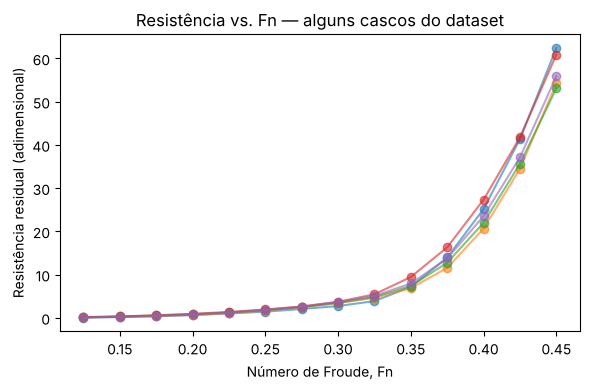

In [4]:
fig, ax = plt.subplots(figsize=(6,4))
for cb in df["center_of_buoyancy"].unique()[:5]:
    sub = df[df["center_of_buoyancy"] == cb].sort_values("froude_number")
    # pega o primeiro casco distinto por combinação de geometria
    for _, geom in sub.groupby(["prismatic_coefficient", "length_displacement"]):
        ax.plot(geom["froude_number"], geom["resistance"], marker="o", alpha=0.6)
        break
ax.set_xlabel("Número de Froude, Fn")
ax.set_ylabel("Resistência residual (adimensional)")
ax.set_title("Resistência vs. Fn — alguns cascos do dataset")
plt.tight_layout()
plt.show()


## 2. Preparar os dados para treino

- **Split treino/teste (80/20):** o modelo só vê os pontos de treino; os de teste medem a capacidade de
  generalização.
- **Padronização** de cada coluna $j$ (entradas e saída), usando média $\bar{x}_j$ e desvio $s_j$
  calculados **apenas no treino**:

$$
\tilde{x}_j = \frac{x_j - \bar{x}_j}{s_j}.
$$

Isso é importante porque as escalas variam muito ($Fn \sim 0.1$–$0.5$, $LCB \sim -5$–$0$,
resistência $\sim 0$–$60$). Na MLP, entradas de escalas parecidas deixam os gradientes bem condicionados;
no RBF, a distância entre pontos $\lVert \mathbf{x}-\mathbf{x}' \rVert$ deixa de ser dominada pela
coluna de maior escala. As predições são depois convertidas de volta para a escala original
($y = \tilde{y}\, s_y + \bar{y}$).

In [5]:
feature_cols = ["center_of_buoyancy", "prismatic_coefficient", "length_displacement",
                "beam_draught_ratio", "length_beam_ratio", "froude_number"]
target_col = "resistance"

X = df[feature_cols].values.astype(np.float32)
y = df[target_col].values.astype(np.float32).reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

X_train_s = x_scaler.transform(X_train).astype(np.float32)
X_test_s = x_scaler.transform(X_test).astype(np.float32)
y_train_s = y_scaler.transform(y_train).astype(np.float32)
y_test_s = y_scaler.transform(y_test).astype(np.float32)

X_train_t = torch.from_numpy(X_train_s)
y_train_t = torch.from_numpy(y_train_s)
X_test_t = torch.from_numpy(X_test_s)
y_test_t = torch.from_numpy(y_test_s)

print("treino:", X_train_t.shape, " teste:", X_test_t.shape)


treino: torch.Size([246, 6])  teste: torch.Size([62, 6])


## 3. Definir a MLP (surrogate model)

Arquitetura pequena de propósito: 6 entradas → 2 camadas ocultas (32, 32) com ativação `tanh` → 1 saída.
Para uma entrada padronizada $\mathbf{x} \in \mathbb{R}^6$, a rede calcula

$$
\mathbf{h}_1 = \tanh(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1), \qquad
\mathbf{h}_2 = \tanh(\mathbf{W}_2 \mathbf{h}_1 + \mathbf{b}_2), \qquad
\hat{y} = \mathbf{w}_3^{\top} \mathbf{h}_2 + b_3 ,
$$

com $\mathbf{W}_1 \in \mathbb{R}^{32\times 6}$, $\mathbf{W}_2 \in \mathbb{R}^{32\times 32}$,
$\mathbf{w}_3 \in \mathbb{R}^{32}$. O conjunto de parâmetros treináveis é
$\boldsymbol{\theta} = \{\mathbf{W}_1, \mathbf{b}_1, \mathbf{W}_2, \mathbf{b}_2, \mathbf{w}_3, b_3\}$:

$$
(6\cdot 32 + 32) + (32\cdot 32 + 32) + (32 + 1) = 224 + 1056 + 33 = 1313 \text{ parâmetros}.
$$

Cada camada faz uma combinação linear seguida de uma não-linearidade suave ($\tanh$). Empilhar camadas
permite representar a forte não-linearidade da resistência perto de $Fn$ alto. O número de parâmetros é
**fixo**, independentemente de quantos pontos de treino existam: isso é o que caracteriza um modelo
paramétrico.

In [6]:
class SurrogateMLP(nn.Module):
    def __init__(self, n_in=6, n_hidden=32, n_out=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_out),
        )

    def forward(self, x):
        return self.net(x)

model = SurrogateMLP()
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("Número de parâmetros:", n_params)


SurrogateMLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Número de parâmetros: 1313


## 4. Treinar

Treinar a MLP significa encontrar os pesos que minimizam o erro quadrático médio (MSE) sobre os
$N$ pontos de treino:

$$
\mathcal{L}(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^{N} \big(\hat{y}(\mathbf{x}_i;\boldsymbol{\theta}) - y_i\big)^2 .
$$

O gradiente $\nabla_{\boldsymbol{\theta}}\mathcal{L}$ é obtido por **backpropagation** (regra da cadeia
aplicada camada a camada, feita automaticamente pelo `loss.backward()` do PyTorch). Os pesos são então
atualizados pelo otimizador **Adam**, uma variante do gradiente descendente

$$
\boldsymbol{\theta}_{k+1} = \boldsymbol{\theta}_k - \eta\, \frac{\hat{\mathbf{m}}_k}{\sqrt{\hat{\mathbf{v}}_k} + \epsilon},
$$

onde $\hat{\mathbf{m}}_k$ e $\hat{\mathbf{v}}_k$ são médias móveis do gradiente e do gradiente ao quadrado,
e $\eta = 10^{-2}$ é a taxa de aprendizado. Cada passo desse laço é uma **época** (aqui usamos o conjunto
de treino inteiro a cada passo). Poucas centenas de épocas bastam; roda em segundos em CPU.

Note a analogia com o resto da disciplina: treinar uma rede **é** um problema de otimização
não-linear sem restrições, resolvido por um método baseado em gradiente.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

n_epochs = 800
history = []

for epoch in range(n_epochs):
    model.train()
    optimizer.zero_grad()
    pred = model(X_train_t)
    loss = loss_fn(pred, y_train_t)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
    if epoch % 100 == 0 or epoch == n_epochs - 1:
        with torch.no_grad():
            test_loss = loss_fn(model(X_test_t), y_test_t).item()
        print(f"epoch {epoch:4d} | train MSE (padronizado) = {loss.item():.4f} | test MSE = {test_loss:.4f}")


epoch    0 | train MSE (padronizado) = 0.9777 | test MSE = 0.4269
epoch  100 | train MSE (padronizado) = 0.0020 | test MSE = 0.0013
epoch  200 | train MSE (padronizado) = 0.0006 | test MSE = 0.0008
epoch  300 | train MSE (padronizado) = 0.0004 | test MSE = 0.0007
epoch  400 | train MSE (padronizado) = 0.0003 | test MSE = 0.0006


epoch  500 | train MSE (padronizado) = 0.0003 | test MSE = 0.0009
epoch  600 | train MSE (padronizado) = 0.0002 | test MSE = 0.0005
epoch  700 | train MSE (padronizado) = 0.0002 | test MSE = 0.0005
epoch  799 | train MSE (padronizado) = 0.0002 | test MSE = 0.0005


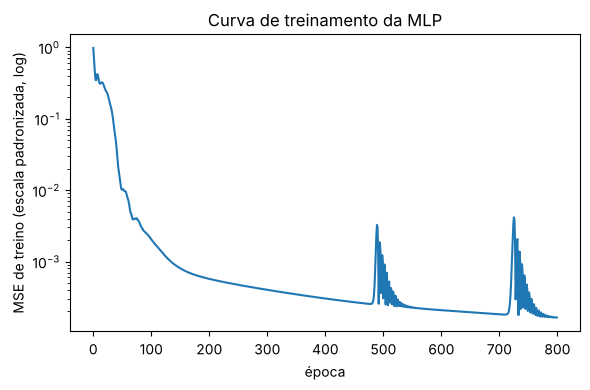

In [8]:
plt.figure(figsize=(6,4))
plt.plot(history)
plt.yscale("log")
plt.xlabel("época")
plt.ylabel("MSE de treino (escala padronizada, log)")
plt.title("Curva de treinamento da MLP")
plt.tight_layout()
plt.show()


## 5. Avaliar: predicted vs. measured

O gráfico clássico de verificação de um surrogate: se os pontos caem sobre a diagonal, o modelo generaliza
bem para os dados de teste (pontos que a rede não viu durante o treino). Duas métricas resumem o ajuste,
calculadas na escala original:

$$
R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2},
\qquad
\text{MAE} = \frac{1}{N}\sum_i |y_i - \hat{y}_i| .
$$

$R^2 = 1$ significa ajuste perfeito; $R^2 = 0$ significa que o modelo não é melhor do que prever sempre a
média. O MAE está nas mesmas unidades da resistência, o que facilita a interpretação de engenharia.

R^2 (teste) = 0.9992   MAE (teste) = 0.258


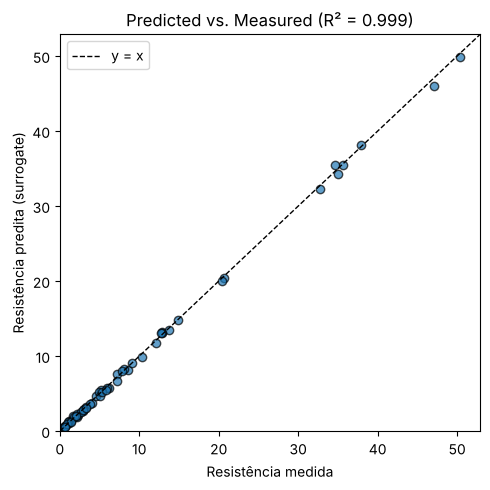

In [9]:
model.eval()
with torch.no_grad():
    pred_test_s = model(X_test_t).numpy()

pred_test = y_scaler.inverse_transform(pred_test_s)
true_test = y_scaler.inverse_transform(y_test_s)

r2 = 1 - np.sum((true_test - pred_test) ** 2) / np.sum((true_test - true_test.mean()) ** 2)
mae = np.mean(np.abs(true_test - pred_test))
print(f"R^2 (teste) = {r2:.4f}   MAE (teste) = {mae:.3f}")

plt.figure(figsize=(5,5))
lims = [0, max(true_test.max(), pred_test.max()) * 1.05]
plt.plot(lims, lims, "k--", lw=1, label="y = x")
plt.scatter(true_test, pred_test, alpha=0.7, edgecolor="k")
plt.xlabel("Resistência medida")
plt.ylabel("Resistência predita (surrogate)")
plt.title(f"Predicted vs. Measured (R² = {r2:.3f})")
plt.legend()
plt.xlim(lims); plt.ylim(lims)
plt.tight_layout()
plt.show()


## 6. A curva de resistência vs. Froude — a MLP reproduz a física?

Fixamos a geometria de um casco (valores médios do dataset) e variamos só o número de Froude, num grid
mais fino do que os 14 pontos originais. Se o surrogate aprendeu a estrutura correta do problema (e não só
"decorou" os pontos), a curva predita deve seguir a mesma forma qualitativa vista na Seção 1: crescimento
suave e depois uma subida acentuada perto de $Fn \approx 0.40$–$0.45$ (regime de formação de ondas).

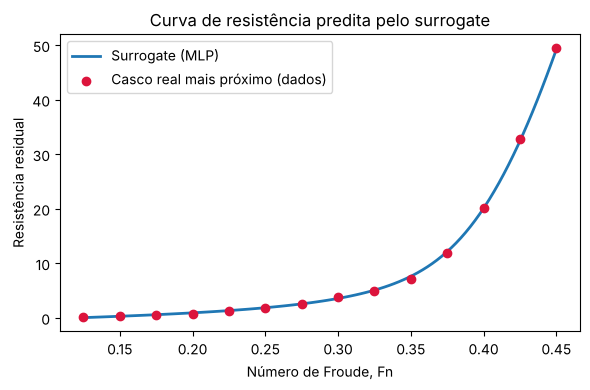

In [10]:
# geometria de referência: valores médios do dataset
base_geom = df[feature_cols[:-1]].mean().values  # tudo menos froude_number

fn_grid = np.linspace(0.125, 0.450, 100)
X_grid = np.tile(base_geom, (len(fn_grid), 1))
X_grid = np.column_stack([X_grid, fn_grid]).astype(np.float32)

X_grid_s = x_scaler.transform(X_grid).astype(np.float32)
with torch.no_grad():
    pred_grid_s = model(torch.from_numpy(X_grid_s)).numpy()
pred_grid = y_scaler.inverse_transform(pred_grid_s)

plt.figure(figsize=(6,4))
plt.plot(fn_grid, pred_grid, lw=2, label="Surrogate (MLP)")

# sobrepõe pontos reais do casco mais próximo da geometria média
dists = np.linalg.norm(df[feature_cols[:-1]].values - base_geom, axis=1)
closest_hull_idx = df.iloc[[dists.argmin()]].index
# pega todos os pontos daquele casco específico (mesma geometria)
geom_ref = df.loc[closest_hull_idx[0], feature_cols[:-1]]
mask = (df[feature_cols[:-1]] - geom_ref).abs().sum(axis=1) < 1e-6
real_points = df[mask].sort_values("froude_number")
plt.scatter(real_points["froude_number"], real_points["resistance"],
            color="crimson", zorder=5, label="Casco real mais próximo (dados)")

plt.xlabel("Número de Froude, Fn")
plt.ylabel("Resistência residual")
plt.title("Curva de resistência predita pelo surrogate")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Conectando com otimização (fecho da aula)

Com o surrogate treinado, uma avaliação de `(geometria, Fn) → resistência` custa microssegundos, contra
horas de CFD/ensaio. Isso é o que torna viável, por exemplo, varrer ou otimizar a geometria do casco para
minimizar resistência em uma faixa de operação. O problema de projeto vira

$$
\min_{\mathbf{g}} \; \bar{R}(\mathbf{g}) = \frac{1}{M}\sum_{m=1}^{M} \hat{f}(\mathbf{g}, Fn_m),
\qquad \mathbf{g} = (LCB, C_P, L/\nabla^{1/3}, B/T, L/B),
$$

em que $\hat{f}$ é o surrogate (MLP ou RBF) e a média é tomada ao longo da faixa de velocidades de
operação. O mesmo surrogate pode ser a função objetivo de grid search, gradiente (MLP e RBF são
diferenciáveis) ou algoritmo evolutivo. Abaixo, uma versão simples: avaliar as 22 geometrias ensaiadas.

In [11]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

# Kernel: sigma_f^2 * RBF(l_1..l_6) + sigma_n^2  (um comprimento de correlação por entrada)
kernel = (ConstantKernel(1.0, (1e-3, 1e3))
          * RBF(length_scale=np.ones(len(feature_cols)), length_scale_bounds=(1e-2, 1e3))
          + WhiteKernel(noise_level=1e-4, noise_level_bounds=(1e-8, 1e-1)))

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5, random_state=0)
gp.fit(X_train_s, y_train_s.ravel())   # mesmos dados padronizados usados na MLP

print("Kernel ajustado:", gp.kernel_)
print(f"Log-verossimilhança marginal: {gp.log_marginal_likelihood_value_:.2f}")


Kernel ajustado: 2.82**2 * RBF(length_scale=[7.4, 12.2, 16.4, 9.16, 2.13, 1.19]) + WhiteKernel(noise_level=0.000126)
Log-verossimilhança marginal: 431.59


### 7.4 O que o RBF aprendeu: comprimentos de correlação

Os $\ell_d$ ajustados funcionam como uma medida de importância de cada entrada (estão na escala
padronizada, então são comparáveis entre si). Espera-se que $Fn$ tenha o menor $\ell$: é a variável que
mais muda a resistência, como vimos na Seção 1.

              entrada  comprimento de correlação l_d
        froude_number                           1.19
    length_beam_ratio                           2.13
   center_of_buoyancy                            7.4
   beam_draught_ratio                           9.16
prismatic_coefficient                           12.2
  length_displacement                           16.4


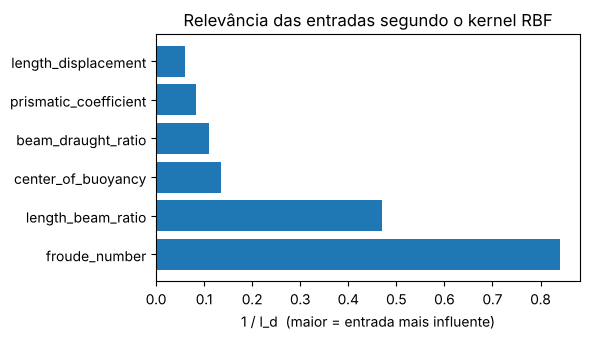

In [12]:
length_scales = gp.kernel_.k1.k2.length_scale
ls_table = pd.DataFrame({"entrada": feature_cols, "comprimento de correlação l_d": length_scales})
ls_table = ls_table.sort_values("comprimento de correlação l_d")
print(ls_table.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

plt.figure(figsize=(6, 3.5))
plt.barh(ls_table["entrada"], 1 / ls_table["comprimento de correlação l_d"])
plt.xlabel("1 / l_d  (maior = entrada mais influente)")
plt.title("Relevância das entradas segundo o kernel RBF")
plt.tight_layout()
plt.show()


### 7.5 Comparação MLP × RBF no conjunto de teste

Mesmos pontos de teste, mesmas métricas ($R^2$ e MAE) da Seção 5. No gráfico do RBF, as barras verticais
mostram $\pm 2\sigma$, o intervalo de aproximadamente 95% de confiança que o próprio modelo informa.

MLP : R^2 = 0.9992   MAE = 0.258
RBF : R^2 = 0.9993   MAE = 0.185


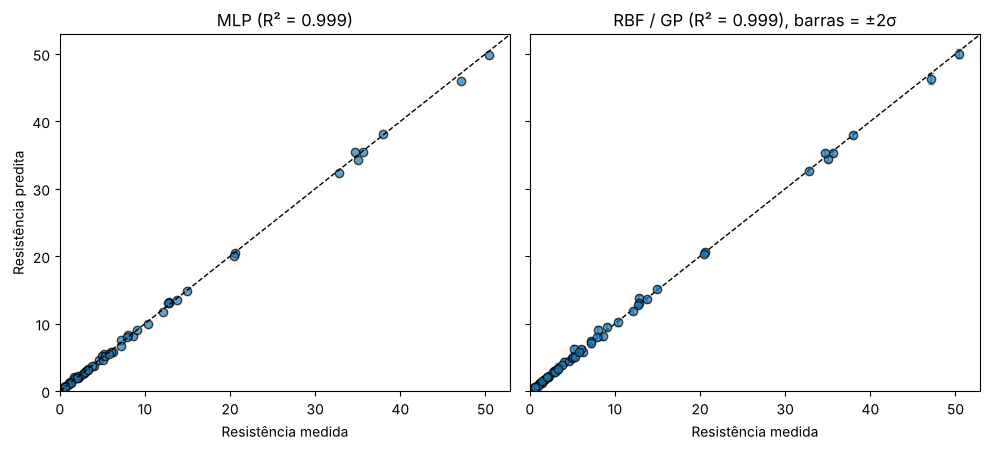

In [13]:
mu_test_s, std_test_s = gp.predict(X_test_s, return_std=True)
mu_test = y_scaler.inverse_transform(mu_test_s.reshape(-1, 1))
std_test = std_test_s * y_scaler.scale_[0]          # desvio volta para a escala original

r2_rbf = 1 - np.sum((true_test - mu_test) ** 2) / np.sum((true_test - true_test.mean()) ** 2)
mae_rbf = np.mean(np.abs(true_test - mu_test))

print(f"MLP : R^2 = {r2:.4f}   MAE = {mae:.3f}")
print(f"RBF : R^2 = {r2_rbf:.4f}   MAE = {mae_rbf:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
lims = [0, max(true_test.max(), pred_test.max(), mu_test.max()) * 1.05]

axes[0].scatter(true_test, pred_test, alpha=0.7, edgecolor="k")
axes[0].set_title(f"MLP (R² = {r2:.3f})")

axes[1].errorbar(true_test.ravel(), mu_test.ravel(), yerr=2 * std_test,
                 fmt="o", alpha=0.7, mec="k", capsize=2)
axes[1].set_title(f"RBF / GP (R² = {r2_rbf:.3f}), barras = ±2σ")

for ax in axes:
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Resistência medida")
axes[0].set_ylabel("Resistência predita")
plt.tight_layout()
plt.show()


### 7.6 Curva de resistência vs. Froude: as duas predições lado a lado

Mesmo casco de referência da Seção 6. A faixa sombreada é a incerteza $\pm 2\sigma$ do RBF. Vale também
testar o que acontece **fora** da faixa ensaiada ($Fn > 0.45$): a MLP extrapola com toda a confiança,
enquanto o RBF sinaliza, pelo aumento de $\sigma$, que está sem dados naquela região.

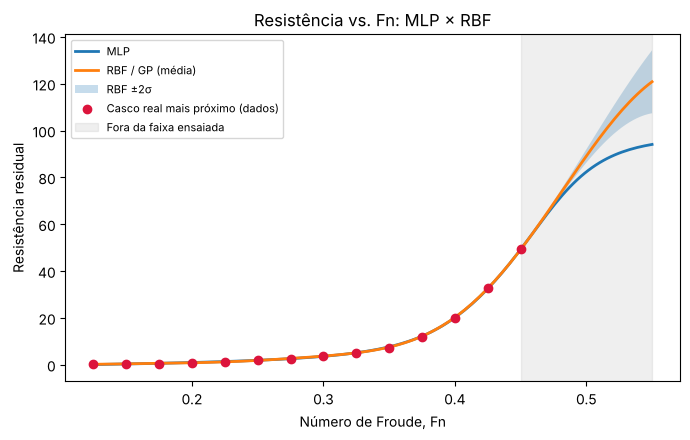

In [14]:
fn_ext = np.linspace(0.125, 0.55, 150)          # inclui uma extrapolação além de Fn = 0.45
X_ext = np.column_stack([np.tile(base_geom, (len(fn_ext), 1)), fn_ext]).astype(np.float32)
X_ext_s = x_scaler.transform(X_ext).astype(np.float32)

with torch.no_grad():
    mlp_ext = y_scaler.inverse_transform(model(torch.from_numpy(X_ext_s)).numpy()).ravel()
mu_ext_s, std_ext_s = gp.predict(X_ext_s, return_std=True)
mu_ext = y_scaler.inverse_transform(mu_ext_s.reshape(-1, 1)).ravel()
std_ext = std_ext_s * y_scaler.scale_[0]

plt.figure(figsize=(7, 4.5))
plt.plot(fn_ext, mlp_ext, lw=2, label="MLP")
plt.plot(fn_ext, mu_ext, lw=2, label="RBF / GP (média)")
plt.fill_between(fn_ext, mu_ext - 2 * std_ext, mu_ext + 2 * std_ext, alpha=0.25, label="RBF ±2σ")
plt.scatter(real_points["froude_number"], real_points["resistance"], color="crimson", zorder=5,
            label="Casco real mais próximo (dados)")
plt.axvspan(0.45, fn_ext.max(), color="grey", alpha=0.12, label="Fora da faixa ensaiada")
plt.xlabel("Número de Froude, Fn")
plt.ylabel("Resistência residual")
plt.title("Resistência vs. Fn: MLP × RBF")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 7.7 Resumo da comparação

| | MLP | RBF / Gaussian Process |
|---|---|---|
| Forma do modelo | $\hat{y} = \mathbf{w}_3^\top \tanh(\mathbf{W}_2 \tanh(\mathbf{W}_1\mathbf{x}+\mathbf{b}_1)+\mathbf{b}_2)+b_3$ | $\mu(\mathbf{x}) = \sum_i \alpha_i\, k(\mathbf{x}, \mathbf{x}_i)$ |
| O que é ajustado | 1313 pesos | 8 hiperparâmetros + $\boldsymbol{\alpha}=K^{-1}\mathbf{y}$ |
| Como | backpropagation + Adam, por épocas | máxima verossimilhança + sistema linear |
| Incerteza | não fornece (precisaria de ensembles, dropout etc.) | fornece $\sigma(\mathbf{x})$ diretamente |
| Interpretação | pesos sem significado físico direto | $\ell_d$ indica a relevância de cada entrada |
| Quando usar | muitos dados, alta dimensão | poucos dados caros (CFD, ensaio), otimização bayesiana |

Para dados de engenharia caros, como ensaios em tanque, o RBF costuma ser a escolha natural:
com poucas centenas de pontos ele já ajusta bem e ainda diz **onde** não confia em si mesmo. A MLP
ganha quando o volume de dados é grande ou quando se quer embutir física na função de perda (Aula 2).

## 7. Conectando com otimização (fecho da aula)

Com o surrogate treinado, uma avaliação de `(geometria, Fn) → resistência` custa microssegundos, contra
horas de CFD/ensaio. Isso é o que torna viável, por exemplo, varrer ou otimizar a geometria do casco para
minimizar resistência em uma faixa de operação — o mesmo surrogate pode virar a função objetivo de um
laço de otimização (grid search, gradiente, ou algoritmo evolutivo), já que a MLP é diferenciável.


In [15]:
# Ilustração simples: qual das 22 geometrias do dataset minimiza a resistência média
# ao longo de toda a faixa de Fn, segundo o surrogate treinado?
geoms = df[feature_cols[:-1]].drop_duplicates().values

best_geom, best_mean_r = None, np.inf
results = []
for g in geoms:
    Xg = np.column_stack([np.tile(g, (len(fn_grid), 1)), fn_grid]).astype(np.float32)
    Xg_s = x_scaler.transform(Xg).astype(np.float32)
    with torch.no_grad():
        pg_s = model(torch.from_numpy(Xg_s)).numpy()
    pg = y_scaler.inverse_transform(pg_s)
    mean_r = pg.mean()
    results.append(mean_r)
    if mean_r < best_mean_r:
        best_mean_r = mean_r
        best_geom = g

print("Resistência média (surrogate) mais baixa entre as 22 geometrias:", round(best_mean_r, 3))
print("Geometria correspondente (center_of_buoyancy, Cp, L/D, B/Dr, L/B):", np.round(best_geom, 3))


Resistência média (surrogate) mais baixa entre as 22 geometrias: 8.361
Geometria correspondente (center_of_buoyancy, Cp, L/D, B/Dr, L/B): [-2.4    0.585  4.78   3.84   3.32 ]


---
**Para a aula:** vale terminar aqui reforçando o fluxo fechado — *dado → surrogate → predição rápida →
avaliação/otimização de projeto* — que é exatamente a ponte para a Aula 2, onde o surrogate deixará de ser
puramente data-driven e passará a incorporar a física da EDP diretamente na função de perda.
